# 03 · Analysis pipeline (confirmatory and exploratory)

This notebook is the whole analysis plan as code. It runs in two modes:

- **`MODE = "synthetic"` (default, before registration).** Every face embedding and every human rating is simulated, with a known answer built in. The pipeline must recover it. Only human-side facts that are already public on the OSF pages are read from the real data: face sets, demographics, reliabilities, the trait correlation structure, the trial layout and the model predictors (alignment, d′, families).
- **`MODE = "real"` (only after registration).** The same code on the real embeddings and ratings. The notebook refuses to run in this mode until `REGISTRATION` holds the registration link.

| Section | What it does | Role |
|---|---|---|
| 0 | Settings and the firewall | |
| 1 | Inputs | |
| 2 | Face-level folds | |
| 3 | Ridge regression with nested cross-validation, unit tests | |
| 4 | Excess-leakage estimator, known-answer tests | |
| 5 | Embeddings and ratings (real, or the synthetic world) | |
| 6 | Trait predictions for every model | |
| 7 | Outcomes per model: L(m), mean trait accuracy, hold-out L(m) | |
| 8 | **H1** with the calibrated test, and an independent re-implementation | confirmatory |
| 9 | H1b: the alignment transformation on unseen faces, with the validation of the training code | secondary |
| 10 | Q2 factor structure | exploratory |
| 11 | Q3 demographic gaps | exploratory |
| 12 | Q4 memorability | exploratory |
| 13 | CFD external check | descriptive |
| 14 | Synthetic recovery check (synthetic mode only) | |
| 15 | Facts table | |

**Outputs** go to `results/analysis/synthetic/` or `results/analysis/real/`, never mixed.

**Run time.** Synthetic mode with the fast settings: about 30–60 minutes, plus about 15–30 minutes once for the transformation validation. Real mode: several hours, most of it training the H1b transformations (placebo and cross-validation, 30 epochs each). TensorFlow runs on the CPU. Slow steps are cached in `cache/<settings>/`; a new setting starts a new cache.

## 0. Settings and the firewall

`MODE = "real"` needs `REGISTRATION` to hold the link of the OSF registration. Leave both alone until the registration exists.

In synthetic mode `FAST = True` shrinks the expensive settings (fewer folds, repeats and bootstrap draws). The real run always uses the full settings below.

In [61]:
import os, json, glob, hashlib, time, warnings
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.linalg import eigh
from scipy.spatial.distance import pdist, squareform

MODE = "synthetic"          # "synthetic" | "real"
REGISTRATION = ""           # OSF registration link; required for MODE = "real"
FAST = True                 # synthetic mode only

if MODE == "real":
    assert REGISTRATION.startswith(("http", "10.")), \
        "FIREWALL: MODE = 'real' only after the OSF registration exists; put its link in REGISTRATION"
    FAST = False
assert MODE in ("synthetic", "real")

REPO = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
ZEN = os.path.join(REPO, "datasets", "external", "hojjati_zenodo")
RAW = os.path.join(REPO, "datasets", "raw")
DATA01 = os.path.join(REPO, "results", "data")
M2 = os.path.join(REPO, "results", "models", "m2")
OUT = os.path.join(REPO, "results", "analysis", MODE)
FIG_DIR = os.path.join(OUT, "figures")
CACHE = os.path.join(OUT, "cache")
for d in (OUT, FIG_DIR, CACHE):
    os.makedirs(d, exist_ok=True)

# ---------------------------------------------------------------- the plan's fixed settings
SEED = 1
N_USAFD, N_CFD = 2222, 597
TRAITS_14 = ["attractive", "emotStable", "normal", "responsible", "trustworthy", "confident", "sociable",
             "caring", "humble", "calm", "happy", "kind", "intelligent", "interesting"]
OTHER_6 = ["typical", "memorable", "emotional", "familiar", "common", "friendly"]
MEM_TARGETS = ["mem_logit_hr", "mem_logit_far", "mem_dprime"]
TARGETS = TRAITS_14 + OTHER_6 + MEM_TARGETS
CFD_TRAITS = ["attractive", "trustworthy", "happy"]

K_OUTER, N_REPEAT, K_INNER = 10, 5, 5            # outer folds x repeats, inner folds for the penalty
ALPHA_REL = np.logspace(-3, 4, 25)               # penalty = ALPHA_REL x n_train (features standardised)
B_WILD = 9999                                    # wild cluster bootstrap draws (H1)
B_CLUSTER = 9999                                 # family bootstrap draws (H1b, Q2-Q4 intervals)
N_PERM_Q2, N_NULL_Q2 = 1000, 1000                # parallel analysis, noise-matched null
H1_ALPHA = 0.025                                 # one-sided
H1B_CV = True                                    # H1b supporting analysis on the main set (5 folds)
CELL_MIN = 50                                    # Q3: race x gender cells below this are descriptive
CFD_MIN_CELL = 20                                # CFD: cells below this are left out of the pooled r
TRANSFORM_IMPL = "hojjati"                       # Hojjati et al.'s released matrices and training code (Zenodo v2)

if MODE == "synthetic" and FAST:
    K_OUTER, N_REPEAT = 5, 1
    B_WILD, B_CLUSTER = 1999, 1999
    N_PERM_Q2, N_NULL_Q2 = 200, 200

rng_master = np.random.default_rng(SEED)

sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})

def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), bbox_inches="tight")

def _json(o):
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    raise TypeError(type(o))

def dump(obj, name):
    json.dump(obj, open(os.path.join(OUT, name), "w"), indent=1, default=_json)

def zs(v):
    v = np.asarray(v, float)
    return (v - v.mean()) / v.std()

def l2norm_rows(x):
    return x / np.linalg.norm(x, axis=1, keepdims=True)

def _walk(root, *parts):
    """Find a file under root whose path ends with the given parts (case-insensitive)."""
    want = os.path.join(*parts).lower()
    for r, _, fs in os.walk(root):
        for f in fs:
            p = os.path.join(r, f)
            if p.lower().endswith(want):
                return p
    raise FileNotFoundError(os.path.join(root, *parts))

print(f"MODE = {MODE}  (FAST = {FAST})")
print(f"outer folds {K_OUTER} x repeats {N_REPEAT}, inner {K_INNER}; wild draws {B_WILD}; transform: {TRANSFORM_IMPL}")
print(f"outputs -> {os.path.relpath(OUT, REPO)}")

MODE = synthetic  (FAST = True)
outer folds 5 x repeats 1, inner 5; wild draws 1999; transform: hojjati
outputs -> results/analysis/synthetic


## 1. Inputs

Read in both modes: face sets, perceived demographics, reliabilities, the trial layout and the model predictors. In real mode the trait scores and memorability are the outcomes' raw material; in synthetic mode they are read only for their correlation structure, and then replaced by simulated ratings in section 5.

In [62]:
fs = pd.read_csv(os.path.join(DATA01, "face_sets.csv"))
MAIN = np.sort(fs.loc[fs.set == "main", "id"].to_numpy())
HOLD = np.sort(fs.loc[fs.set == "holdout", "id"].to_numpy())
CFD = np.sort(fs.loc[fs.set == "cfd", "id"].to_numpy())
assert (len(MAIN), len(HOLD), len(CFD)) == (1678, 544, 597)

# ---- perceived demographics (Bainbridge 'Final Values', as in notebook 01) ----
RACE = ["Other", "White", "Black", "East Asian", "South Asian", "Hispanic", "Middle Eastern"]
_dv = pd.read_excel(_walk(RAW, "2kattributes", "demographic & others labels",
                          "demographic-others-labels.xlsx"), sheet_name="Final Values")
demo = pd.DataFrame({"id": _dv["Image #"].astype(int)}).set_index("id")
demo["race"] = [RACE[int(v)] if pd.notna(v) else "Missing" for v in _dv["Race"]]
demo["gender"] = [("Female", "Male")[int(v)] if pd.notna(v) else "Missing" for v in _dv["Gender"]]
demo["age"] = _dv["Age"].astype(float).to_numpy()            # mean of 12 five-level codes, continuous
demo["white"] = (demo.race == "White").astype(int)
demo["female"] = (demo.gender == "Female").astype(int)
assert len(demo) == N_USAFD

# ---- reliabilities (notebook 01, all raters, Spearman-Brown) ----
rel = pd.read_csv(os.path.join(DATA01, "reliability.csv")).set_index("trait")
R20 = rel.loc[TRAITS_14 + OTHER_6, "sb_spearman_brown"].to_numpy(float)
R14 = R20[:14]
RHALF20 = rel.loc[TRAITS_14 + OTHER_6, "r_half"].to_numpy(float)

# ---- trial layout (for H1b) ----
tr_raw = np.load(os.path.join(ZEN, "Split_data", "All_Similarity_trials.npy"))
sc_raw = np.load(os.path.join(ZEN, "Split_data", "All_Similarity_scores.npy"))
ok_rows = ~np.all(tr_raw == 0, axis=1)
TRIALS, SCORES_REAL = tr_raw[ok_rows].astype(int), sc_raw[ok_rows].astype(float)
assert len(TRIALS) == 33465
assert not np.isin(HOLD - 1, TRIALS).any()

# ---- model predictors: 14 core (notebook 01) + extensions (notebook 02) ----
CORE_STEMS = {
    "ArcFace18": "ARCFace18_glint360k_embs", "ArcFace34": "ARCFace34_glint360k_embs",
    "ArcFace50": "ARCFace50_glint360k_embs", "ArcFace100": "ARCFace100_glint360k_embs",
    "swinface": "swinface_embs", "FaceNet": "Facenet_embs", "FaceNet512": "Facenet512_embs",
    "Dlib": "Dlib_embs", "VGG-Face": "VGG-Face_embs", "GhostFaceNet": "GhostFaceNet_embs",
    "SFace": "SFace_embs", "DeepFace": "DeepFace_embs", "OpenFace": "OpenFace_embs", "DeepID": "DeepID_embs"}
mt = pd.read_csv(os.path.join(DATA01, "models_table.csv"))
core = mt[mt.model.isin(CORE_STEMS)][["model", "family", "emb_dim", "align_usafd", "dprime"]].copy()
core["source"] = "release"
ext = pd.read_csv(os.path.join(M2, "extras.csv")).rename(columns={"align": "align_usafd"})
ext_dims = pd.read_csv(os.path.join(M2, "predictors_m2.csv")).set_index("model")["emb_dim"]
ext["emb_dim"] = ext.model.map(ext_dims).astype(int)
ext["source"] = "own extraction"
MODELS = pd.concat([core, ext[core.columns]], ignore_index=True)
assert len(core) == 14 and MODELS.model.is_unique
FAMS = {f: i for i, f in enumerate(dict.fromkeys(MODELS.family))}
MODELS["fam_idx"] = MODELS.family.map(FAMS)
N_MODELS, N_FAM = len(MODELS), len(FAMS)
print(f"{N_MODELS} models in {N_FAM} families")
print(MODELS[["model", "family", "emb_dim", "align_usafd", "dprime", "source"]].to_string(index=False))

# ---- real trait scores and memorability (structure only in synthetic mode) ----
ts = pd.read_csv(os.path.join(DATA01, "trait_scores_20.csv")).rename(columns={"label": "id"}).set_index("id")
Y20_REAL = ts.loc[np.arange(1, N_USAFD + 1), TRAITS_14 + OTHER_6].to_numpy(float)

mem = pd.read_excel(_walk(RAW, "2kmemorability", "memorability-scores.xlsx"))
assert len(mem) == N_USAFD, "memorability rows must equal the 2,222 faces (same order as target-filenames.txt)"
def _logit(p):
    p = np.clip(np.asarray(p, float), 0.5 / 100, 1 - 0.5 / 100)
    return np.log(p / (1 - p))
_hr, _far = mem["Hit Rate (HR)"].to_numpy(float), mem["False Alarm Rate (FAR)"].to_numpy(float)
MEM_REAL = np.column_stack([_logit(_hr), _logit(_far),
                            stats.norm.ppf(np.clip(_hr, 1e-6, 1 - 1e-6)) - stats.norm.ppf(np.clip(_far, 1e-6, 1 - 1e-6))])

cfd_tab = pd.read_csv(os.path.join(DATA01, "cfd_faces.csv")).set_index("face_id")
_cfd_cols = {t: next(c for c in cfd_tab.columns if c.lower() == t) for t in CFD_TRAITS}
CFD_REAL = cfd_tab.loc[CFD, [_cfd_cols[t] for t in CFD_TRAITS]].to_numpy(float)
CFD_CELL = (cfd_tab.loc[CFD, "race"].astype(str) + "/" + cfd_tab.loc[CFD, "gender"].astype(str)).to_numpy()
print(f"\nface sets: main {len(MAIN)}, hold-out {len(HOLD)}, CFD {len(CFD)}; trials {len(TRIALS)}")

16 models in 12 families
       model          family  emb_dim  align_usafd    dprime         source
        Dlib            Dlib      128     0.297108  3.249591        release
  FaceNet512         FaceNet      512     0.247877  4.190707        release
     FaceNet         FaceNet      128     0.247798  4.620717        release
    VGG-Face        VGG-Face     4096     0.238400  4.091641        release
GhostFaceNet    GhostFaceNet      512     0.190163  3.394029        release
    OpenFace        OpenFace      128     0.178716  1.105882        release
   ArcFace18         ArcFace      512     0.178198  6.295395        release
       SFace           SFace      128     0.176088  3.368330        release
    DeepFace        DeepFace     4096     0.167771  1.321380        release
   ArcFace34         ArcFace      512     0.157336  8.051412        release
   ArcFace50         ArcFace      512     0.141943  8.620870        release
    swinface        SwinFace      512     0.138980  7.202787   

## 2. Face-level folds

Folds are built over the 1,678 main faces, stratified by gender × White/non-White: 10 folds repeated 5 times (seed 1). Every face is an evaluation face exactly once per repeat. The partition is written once to `results/analysis/folds_10x5.csv` and frozen; later runs check that the code still produces exactly that file. The fast synthetic run uses a smaller 5 × 1 partition for speed.

In [63]:
def make_folds(ids, strata, k, repeats, seed):
    rng = np.random.default_rng(seed)
    out = np.zeros((repeats, len(ids)), int)
    for r in range(repeats):
        for s in np.unique(strata):
            idx = np.flatnonzero(strata == s)
            idx = idx[rng.permutation(len(idx))]
            out[r, idx] = (np.arange(len(idx)) + rng.integers(k)) % k
    return out

strata_main = (demo.loc[MAIN, "female"].astype(str) + demo.loc[MAIN, "white"].astype(str)).to_numpy()
FOLDS_PLAN = make_folds(MAIN, strata_main, 10, 5, SEED)                  # the registered partition
plan_path = os.path.join(REPO, "results", "analysis", "folds_10x5.csv")
plan_df = pd.DataFrame(FOLDS_PLAN.T, index=pd.Index(MAIN, name="id"), columns=[f"repeat{r + 1}" for r in range(5)])
if os.path.exists(plan_path):                                            # frozen file must not change
    assert pd.read_csv(plan_path, index_col="id").equals(plan_df), "folds_10x5.csv differs from the code's partition"
else:
    plan_df.to_csv(plan_path)
FOLDS = FOLDS_PLAN if (K_OUTER, N_REPEAT) == (10, 5) else make_folds(MAIN, strata_main, K_OUTER, N_REPEAT, SEED)
for r in range(N_REPEAT):
    sizes = np.bincount(FOLDS[r], minlength=K_OUTER)
    assert sizes.min() >= len(MAIN) // K_OUTER - 2
print(f"folds: {K_OUTER} x {N_REPEAT}; fold sizes (repeat 1): {np.bincount(FOLDS[0]).tolist()}")
fem_share = pd.crosstab(FOLDS[0], demo.loc[MAIN, "female"].to_numpy(), normalize="index")[1]
print(f"share female per fold (repeat 1): {fem_share.round(3).tolist()}")

folds: 5 x 1; fold sizes (repeat 1): [337, 335, 335, 335, 336]
share female per fold (repeat 1): [0.424, 0.424, 0.427, 0.427, 0.426]


## 3. Ridge regression with nested cross-validation

For each training set: standardise the features (training means and SDs only), centre the targets, and choose the penalty **per target** by `K_INNER`-fold cross-validation over 25 log-spaced values (`ALPHA_REL` × the number of training faces). The chosen penalty is refitted on the whole training set and applied to the evaluation faces. The solver uses one eigendecomposition per training set (of XᵀX, or of XXᵀ when there are more features than faces), so every penalty costs almost nothing.

Three unit tests: the solver equals the closed-form ridge solution; no evaluation face is ever in a training set; every main-set prediction is out-of-fold.

In [64]:
def ridge_path(Xtr, Ytr, Xte, alphas):
    """Predictions for every penalty: array (n_alpha, n_test, n_targets)."""
    mu, sd = Xtr.mean(0), Xtr.std(0)
    sd[sd == 0] = 1.0
    A, B = (Xtr - mu) / sd, (Xte - mu) / sd
    ym = Ytr.mean(0)
    Yc = Ytr - ym
    n, p = A.shape
    if p <= n:
        lam, V = eigh(A.T @ A)
        left, right = B @ V, V.T @ (A.T @ Yc)
    else:
        lam, U = eigh(A @ A.T)
        left, right = (B @ A.T) @ U, U.T @ Yc
    lam = np.clip(lam, 0, None)
    return np.stack([left @ (right / (lam + a)[:, None]) for a in alphas]) + ym

def ridge_cv_fit_predict(Xtr, Ytr, Xte_list, seed):
    """Penalty per target by inner CV, then refit; returns predictions for each test matrix and the penalties."""
    n = len(Xtr)
    alphas = ALPHA_REL * n * (K_INNER - 1) / K_INNER
    inner = np.random.default_rng(seed).permutation(n) % K_INNER
    sse = np.zeros((len(alphas), Ytr.shape[1]))
    for f in range(K_INNER):
        tr, va = inner != f, inner == f
        P = ridge_path(Xtr[tr], Ytr[tr], Xtr[va], alphas)
        sse += ((P - Ytr[va][None]) ** 2).sum(1)
    best = sse.argmin(0)
    alphas_full = ALPHA_REL * n
    outs = []
    for Xte in Xte_list:
        P = ridge_path(Xtr, Ytr, Xte, alphas_full)
        outs.append(P[best, :, np.arange(Ytr.shape[1])].T)
    return outs, best

# ---- unit test 1: equals the closed-form solution ----
_r = np.random.default_rng(0)
for p_ in (30, 300):                                   # primal and dual branches
    Xa, Ya, Xb = _r.normal(size=(120, p_)), _r.normal(size=(120, 3)), _r.normal(size=(40, p_))
    mu, sd = Xa.mean(0), Xa.std(0)
    A_, B_ = (Xa - mu) / sd, (Xb - mu) / sd
    for a in (0.5, 50.0):
        coef = np.linalg.solve(A_.T @ A_ + a * np.eye(p_), A_.T @ (Ya - Ya.mean(0)))
        ref = B_ @ coef + Ya.mean(0)
        got = ridge_path(Xa, Ya, Xb, [a])[0]
        assert np.allclose(got, ref, atol=1e-8), "ridge solver differs from closed form"
print("unit test 1 (closed form, primal and dual): PASS")

unit test 1 (closed form, primal and dual): PASS


## 4. Excess-leakage estimator

For a model's out-of-fold predictions P (faces × 14 traits) and the human trait scores Y of the same faces:

- ρᵢ = corr(Pᵢ, Yᵢ): accuracy for trait i; Lᵢⱼ = corr(Pᵢ, Yⱼ): how much the prediction of i tracks the human score of j; rᵢⱼ = corr(Yᵢ, Yⱼ); Rᵢ = reliability of trait i.
- **Excess leakage** ELᵢⱼ = Lᵢⱼ − ρᵢ·rᵢⱼ / Rᵢ (primary, reliability-corrected) and ELᵢⱼ = Lᵢⱼ − ρᵢ·rᵢⱼ (uncorrected, secondary).
- **L(m)** = mean of sign(rᵢⱼ)·ELᵢⱼ over the 182 ordered pairs i ≠ j. Pearson correlations throughout.

**Known-answer tests.** (KA1) When predictions carry no leakage (Pᵢ = aᵢ·Tᵢ + independent noise, Tᵢ the true trait) the corrected ELᵢⱼ is 0 for every pair; dividing by Rⱼ instead of Rᵢ must fail this test. (KA2) Injected leakage raises L(m) monotonically.

In [65]:
def corr_cross(P, Y):
    Pz = (P - P.mean(0)) / P.std(0)
    Yz = (Y - Y.mean(0)) / Y.std(0)
    return Pz.T @ Yz / len(P)

def excess_leakage(P, Y, R, r=None, wrong_index=False):
    L = corr_cross(P, Y)
    rho = np.diag(L).copy()
    r = np.corrcoef(Y.T) if r is None else r
    k = len(rho)
    off = ~np.eye(k, dtype=bool)
    denom = (R[None, :] if wrong_index else R[:, None])
    EL = L - rho[:, None] * r / denom
    ELu = L - rho[:, None] * r
    s = np.sign(r)
    return dict(L=float((s * EL)[off].mean()), L_unc=float((s * ELu)[off].mean()),
                rho=rho, mean_rho=float(rho.mean()), EL=EL)

def psd_corr(C):
    w, V = np.linalg.eigh((C + C.T) / 2)
    C2 = V @ np.diag(np.clip(w, 1e-4, None)) @ V.T
    d = np.sqrt(np.diag(C2))
    return C2 / np.outer(d, d)

# latent correlation of the 14 traits: human correlations disattenuated by reliability (main set)
_r14 = np.corrcoef(Y20_REAL[MAIN - 1][:, :14].T)
SIGMA_T14 = psd_corr(_r14 / np.sqrt(np.outer(R14, R14)))

def ka_world(n, a, lam, seed):
    g = np.random.default_rng(seed)
    T = g.multivariate_normal(np.zeros(14), SIGMA_T14, size=n)
    Y = np.sqrt(R14) * T + np.sqrt(1 - R14) * g.normal(size=T.shape)
    mix = (T.sum(1, keepdims=True) - T) / 13.0
    S = T + lam * mix
    P = a * (S / S.std(0)) + g.normal(size=T.shape)
    return P, Y

a_vec = np.linspace(0.3, 1.2, 14)
P_, Y_ = ka_world(200_000, a_vec, 0.0, 11)
ok_ = excess_leakage(P_, Y_, R14)
bad_ = excess_leakage(P_, Y_, R14, wrong_index=True)
off_ = ~np.eye(14, dtype=bool)
print(f"KA1 no leakage, n = 200,000: L(m) = {ok_['L']:+.4f}, max |EL_ij| = {np.abs(ok_['EL'][off_]).max():.4f}; "
      f"dividing by R_j: max |EL_ij| = {np.abs(bad_['EL'][off_]).max():.4f}")
assert abs(ok_["L"]) < 0.005 and np.abs(ok_["EL"][off_]).max() < 0.01, "KA1 FAILED"
assert np.abs(bad_["EL"][off_]).max() > 0.02, "KA1 control FAILED: the wrong index is not detected"
print("KA1: PASS (and the wrong-index control fails, as it must)")

dose = []
for lam in (0.0, 0.05, 0.10, 0.20):
    P_, Y_ = ka_world(100_000, a_vec, lam, 12)
    dose.append(excess_leakage(P_, Y_, R14)["L"])
print("KA2 injected leakage 0 / .05 / .10 / .20 -> L(m) =", [round(v, 4) for v in dose])
assert all(np.diff(dose) > 0), "KA2 FAILED"
print("KA2: PASS")
del P_, Y_

KA1 no leakage, n = 200,000: L(m) = -0.0003, max |EL_ij| = 0.0042; dividing by R_j: max |EL_ij| = 0.1300
KA1: PASS (and the wrong-index control fails, as it must)
KA2 injected leakage 0 / .05 / .10 / .20 -> L(m) = [0.0003, 0.0057, 0.0107, 0.0198]
KA2: PASS


## 5. Embeddings and ratings

**Real mode:** the 14 released embedding arrays and the two arrays extracted in notebook 02 (2,819 rows each, row = face id − 1), the real trait scores, memorability and CFD ratings, and the real human similarity rankings.

**Synthetic mode:** a simulated world with the same faces, sets, demographics, reliabilities and trait structure.

- Each face has 20 latent traits with the disattenuated human correlation structure. Ratings are latent + rating noise at each trait's real reliability.
- The latent traits split into a general factor and trait-specific parts. Each model's embedding carries the general factor at full strength and the trait-specific parts at strength sₘ, mixed into the model's real number of dimensions with noise. A weak sₘ makes every trait prediction lean on the general factor, which is leakage.
- **Built-in H1 effect:** log sₘ = log S0 + `SYN_KAPPA`·z(alignment) + family effect + noise. With `SYN_KAPPA` > 0, more aligned models leak less. Set `SYN_KAPPA = 0` to check that H1 is then not supported.
- Synthetic similarity rankings come from a hidden "human face space"; embeddings carry part of it, so a learned transformation can raise alignment (used only to exercise H1b).

In [66]:
SYN_KAPPA = 0.6         # built-in effect: + 1 SD alignment multiplies the trait-specific signal by e^0.6
SYN_S0 = 0.6
SYN_FAMILY_SD, SYN_MODEL_SD = 0.15, 0.10

def load_real():
    E = {}
    for r in MODELS.itertuples():
        f = (os.path.join(ZEN, "Similarity_task_images_embeds", f"{CORE_STEMS[r.model]}.npy") if r.source == "release"
             else os.path.join(M2, "cache", f"{r.model}_stim.npy"))
        try:
            arr = np.load(f).astype(np.float64)
            assert arr.shape == (N_USAFD + N_CFD, r.emb_dim) and np.isfinite(arr).all()
            E[r.model] = arr
        except Exception as ex:
            print(f"{r.model}: embedding check failed ({type(ex).__name__})")
    return E, Y20_REAL, MEM_REAL, CFD_REAL, SCORES_REAL, None

def make_synthetic(seed):
    g = np.random.default_rng(seed)
    n_all = N_USAFD + N_CFD
    r20 = np.corrcoef(Y20_REAL[MAIN - 1].T)
    S20 = psd_corr(r20 / np.sqrt(np.outer(R20, R20)))
    T = g.multivariate_normal(np.zeros(20), S20, size=n_all)
    w, V = np.linalg.eigh(S20)
    v1 = V[:, -1] * np.sign(V[:, -1].sum())
    load = v1 * np.sqrt(w[-1])
    gen = T @ v1 / np.sqrt(w[-1])                                  # general factor (unit variance)
    spec = T - np.outer(gen, load)                                  # trait-specific parts
    mem_lat = 0.25 * T[:, 1] + 0.2 * T[:, 3] + 0.9 * g.normal(size=n_all)   # memorability latent
    F = g.normal(size=(n_all, 8))                                   # face-shape space seen by people
    Y = (np.sqrt(R20) * T + np.sqrt(1 - R20) * g.normal(size=T.shape)) * 1.2 + 5.0
    hr = 1 / (1 + np.exp(-(0.0 + 0.6 * mem_lat + 0.3 * g.normal(size=n_all))))
    far = 1 / (1 + np.exp(-(-1.8 + 0.3 * g.normal(size=n_all))))
    MEMS = np.column_stack([_logit(hr), _logit(far), stats.norm.ppf(hr) - stats.norm.ppf(far)])
    cfdY = np.sqrt(0.85) * T[N_USAFD:][:, [0, 4, 10]] + np.sqrt(0.15) * g.normal(size=(N_CFD, 3))
    # human similarity scores: distance in (face shape + 0.4 x traits) space, plus noise
    H = np.column_stack([F, 0.4 * T[:, :6]])
    d = np.linalg.norm(H[TRIALS[:, :1]] - H[TRIALS[:, 1:]], axis=2) + 0.8 * g.normal(size=(len(TRIALS), 4))
    scores = np.column_stack([TRIALS[:, 0], d])
    za = zs(MODELS.align_usafd)
    fam_eff = g.normal(scale=SYN_FAMILY_SD, size=N_FAM)[MODELS.fam_idx]
    log_s = np.log(SYN_S0) + SYN_KAPPA * za + fam_eff + g.normal(scale=SYN_MODEL_SD, size=N_MODELS)
    E, truth = {}, {}
    for (r, ls, a) in zip(MODELS.itertuples(), log_s, za):
        s = np.exp(ls)
        sig = np.column_stack([gen, s * spec, 0.6 * mem_lat, (0.5 + 0.25 * a) * F])
        M = g.normal(size=(sig.shape[1], r.emb_dim)) / np.sqrt(sig.shape[1])
        E[r.model] = sig @ M * 3.0 + g.normal(size=(n_all, r.emb_dim))
        truth[r.model] = dict(s=float(s))
    world = dict(T=T, gen=gen, spec=spec, mem_lat=mem_lat, F=F, log_s=log_s, S20=S20)
    return E, Y[:N_USAFD], MEMS[:N_USAFD], cfdY, scores, (truth, world)

# cache folder keyed by everything that changes the predictions, so a stale cache is never reused
_sig = json.dumps(dict(mode=MODE, fast=FAST, kappa=SYN_KAPPA, s0=SYN_S0, folds=[K_OUTER, N_REPEAT, K_INNER],
                       alpha=ALPHA_REL.tolist(), seed=SEED, transform=TRANSFORM_IMPL,
                       models=MODELS[["model", "emb_dim"]].values.tolist()))
CACHE = os.path.join(OUT, "cache", hashlib.sha256(_sig.encode()).hexdigest()[:12])
os.makedirs(CACHE, exist_ok=True)
t0 = time.time()
if MODE == "real":
    EMB, Y20, MEMV, CFDY, SCORES, SYN = load_real()
    missing = [m for m in MODELS.model if m not in EMB]
    if missing:                                    # Rules and fallbacks: leave the model out everywhere
        print("LEFT OUT (failed checks):", missing)
        MODELS = MODELS[~MODELS.model.isin(missing)].reset_index(drop=True)
        FAMS = {f: i for i, f in enumerate(dict.fromkeys(MODELS.family))}
        MODELS["fam_idx"] = MODELS.family.map(FAMS)
        N_MODELS, N_FAM = len(MODELS), len(FAMS)
    H1_DESCRIPTIVE_ONLY = N_MODELS < 12 or N_FAM < 9
else:
    EMB, Y20, MEMV, CFDY, SCORES, SYN = make_synthetic(SEED + 100)
    H1_DESCRIPTIVE_ONLY = False
YALL = np.column_stack([Y20, MEMV])                      # targets for the 2,222 USAFD faces, TARGETS order
assert YALL.shape == (N_USAFD, len(TARGETS))
print(f"{MODE} embeddings for {len(EMB)} models ready ({time.time() - t0:.0f}s); "
      f"dims {sorted({e.shape[1] for e in EMB.values()})}")

synthetic embeddings for 16 models ready (1s); dims [128, 160, 512, 4096]


## 6. Trait predictions for every model

For each model and repeat: out-of-fold predictions of all 23 targets for the 1,678 main faces. Then one fit on all main faces predicts the 544 hold-out faces and the 597 CFD faces. Features are the L2-normalised embeddings. Results are cached per model.

In [67]:
def predict_model(name, E, Y):
    f = os.path.join(CACHE, f"pred_{name}.npz")
    if os.path.exists(f):
        z = np.load(f)
        return dict(oof=z["oof"], hold=z["hold"], cfd=z["cfd"], alpha_idx=z["alpha_idx"])
    X = l2norm_rows(E)
    Xm, Ym = X[MAIN - 1], Y[MAIN - 1]
    oof = np.full((N_REPEAT, len(MAIN), Y.shape[1]), np.nan)
    a_idx = []
    for r in range(N_REPEAT):
        for k in range(K_OUTER):
            te = FOLDS[r] == k
            tr = ~te
            assert not np.intersect1d(MAIN[tr], MAIN[te]).size          # unit test 2
            (P,), best = ridge_cv_fit_predict(Xm[tr], Ym[tr], [Xm[te]], seed=SEED + 1000 * r + k)
            oof[r, te] = P
            a_idx.append(best)
    assert np.isfinite(oof).all()                                      # unit test 3: every face predicted once per repeat
    (Ph, Pc), best = ridge_cv_fit_predict(Xm, Ym, [X[HOLD - 1], X[CFD - 1]], seed=SEED + 99)
    a_idx.append(best)
    out = dict(oof=oof, hold=Ph, cfd=Pc, alpha_idx=np.array(a_idx))
    np.savez_compressed(f, **out)
    return out

PRED = {}
t0 = time.time()
for r in MODELS.itertuples():
    PRED[r.model] = predict_model(r.model, EMB[r.model], YALL)
    edge = np.isin(PRED[r.model]["alpha_idx"], [0, len(ALPHA_REL) - 1]).mean()
    print(f"{r.model:14s} done ({time.time() - t0:5.0f}s); penalties at the grid edge: {100 * edge:.0f}%")
print("unit tests 2 (no evaluation face in training) and 3 (all predictions out-of-fold): PASS")

Dlib           done (    0s); penalties at the grid edge: 4%
FaceNet512     done (    0s); penalties at the grid edge: 4%
FaceNet        done (    0s); penalties at the grid edge: 4%
VGG-Face       done (    0s); penalties at the grid edge: 4%
GhostFaceNet   done (    0s); penalties at the grid edge: 4%
OpenFace       done (    0s); penalties at the grid edge: 4%
ArcFace18      done (    0s); penalties at the grid edge: 4%
SFace          done (    0s); penalties at the grid edge: 3%
DeepFace       done (    0s); penalties at the grid edge: 3%
ArcFace34      done (    0s); penalties at the grid edge: 2%
ArcFace50      done (    0s); penalties at the grid edge: 2%
swinface       done (    0s); penalties at the grid edge: 1%
ArcFace100     done (    0s); penalties at the grid edge: 2%
DeepID         done (    0s); penalties at the grid edge: 2%
w600k_r50      done (    0s); penalties at the grid edge: 2%
IRV1-casia     done (    0s); penalties at the grid edge: 4%
unit tests 2 (no evaluat

## 7. Outcomes per model

- **L(m), main set** (primary outcome): excess leakage of the out-of-fold predictions of the 14 traits, computed on each repeat and averaged over repeats. rᵢⱼ is computed on the main faces' human scores.
- **Mean trait accuracy** = mean ρᵢ over the 14 traits (an H1 covariate).
- **L(m), hold-out**: the same estimator on the 544 hold-out faces (predictions from the fit on all main faces; rᵢⱼ from the hold-out faces' human scores). It decides H1's third condition.
- **Halo sensitivity** (real mode): rᵢⱼ from independent raters (trait i scored by one random half of the raters, trait j by the other half, rescaled to full-score reliability; 50 splits).

In [68]:
k14 = slice(0, 14)
Ym14, Yh14 = YALL[MAIN - 1][:, k14], YALL[HOLD - 1][:, k14]
r_main, r_hold = np.corrcoef(Ym14.T), np.corrcoef(Yh14.T)

def independent_rater_r(ids, n_split=50):
    """r_ij with trait i and trait j scored by different raters (real mode only)."""
    psy = pd.read_excel(_walk(RAW, "2kattributes", "psychology attributes", "psychology-attributes.xlsx"),
                        sheet_name="All Data")
    psy = psy[psy["Image #"].isin(ids)]
    ANT = {"attractive": "unattractive", "emotStable": "emotUnstable", "normal": "weird",
           "responsible": "irresponsible", "trustworthy": "untrustworthy", "confident": "uncertain",
           "sociable": "introverted", "caring": "cold", "humble": "egotistic", "calm": "aggressive",
           "happy": "unhappy", "kind": "mean", "intelligent": "unintelligent", "interesting": "boring"}
    cols = list(psy.columns)
    block = {c: "subID" for c in cols[2:28]} | {c: "subID.1" for c in cols[28:54]}
    lab = {v: i for i, v in enumerate(sorted(ids))}
    n = len(lab)
    def half_scores(trait, half_of):
        out = []
        for h in (0, 1):
            s = np.zeros(n); c = np.zeros(n)
            for col, sign in ((trait, 1), (ANT[trait], -1)):
                sub = psy[["Image #", block[col], col]].dropna()
                keep = sub[block[col]].map(half_of).to_numpy() == h
                fi = sub["Image #"].map(lab).to_numpy()[keep]
                v = sub[col].to_numpy(float)[keep]
                v = v if sign == 1 else 10 - v
                s += np.bincount(fi, v, n); c += np.bincount(fi, minlength=n)
            out.append(s / np.maximum(c, 1))
        return out
    raters = pd.unique(pd.concat([psy["subID"], psy["subID.1"]]).dropna())
    g = np.random.default_rng(SEED)
    acc = np.zeros((14, 14))
    for _ in range(n_split):
        half_of = dict(zip(raters, g.integers(0, 2, len(raters))))
        H = [half_scores(t, half_of) for t in TRAITS_14]
        for i in range(14):
            for j in range(14):
                if i != j:
                    acc[i, j] += np.corrcoef(H[i][0], H[j][1])[0, 1]
    rab = acc / n_split
    rh = RHALF20[:14]
    r_ind = rab * np.sqrt(np.outer(R14, R14) / np.outer(rh, rh))
    np.fill_diagonal(r_ind, 1.0)
    return r_ind

R_IND = independent_rater_r(MAIN) if MODE == "real" else None

rows, rho_rows = [], []
TRACC = None
for r in MODELS.itertuples():
    pr = PRED[r.model]
    per_rep = [excess_leakage(pr["oof"][k][:, k14], Ym14, R14, r_main) for k in range(N_REPEAT)]
    hold = excess_leakage(pr["hold"][:, k14], Yh14, R14, r_hold)
    row = dict(model=r.model, family=r.family, align=r.align_usafd, dprime=r.dprime,
               L=np.mean([e["L"] for e in per_rep]), L_unc=np.mean([e["L_unc"] for e in per_rep]),
               L_sd_repeats=np.std([e["L"] for e in per_rep]),
               mean_rho=np.mean([e["mean_rho"] for e in per_rep]),
               L_hold=hold["L"], L_hold_unc=hold["L_unc"], mean_rho_hold=hold["mean_rho"])
    if R_IND is not None:
        row["L_halo"] = np.mean([excess_leakage(pr["oof"][k][:, k14], Ym14, R14, R_IND)["L"] for k in range(N_REPEAT)])
    rows.append(row)
    rho_rows.append(dict(model=r.model, **dict(zip(TRAITS_14, np.mean([e["rho"] for e in per_rep], 0)))))
OUTC = pd.DataFrame(rows)
OUTC.to_csv(os.path.join(OUT, "outcomes_by_model.csv"), index=False)
TRACC = pd.DataFrame(rho_rows).set_index("model")
TRACC.to_csv(os.path.join(OUT, "trait_accuracy_by_model.csv"))
print(OUTC.round(4).to_string(index=False))

       model          family  align  dprime       L  L_unc  L_sd_repeats  mean_rho  L_hold  L_hold_unc  mean_rho_hold
        Dlib            Dlib 0.2971  3.2496 -0.0083 0.1278           0.0    0.8567  0.0022      0.1300         0.8500
  FaceNet512         FaceNet 0.2479  4.1907 -0.0001 0.1386           0.0    0.8727  0.0132      0.1431         0.8635
     FaceNet         FaceNet 0.2478  4.6207  0.0105 0.1467           0.0    0.8568  0.0239      0.1514         0.8479
    VGG-Face        VGG-Face 0.2384  4.0916 -0.0058 0.1336           0.0    0.8760  0.0053      0.1363         0.8700
GhostFaceNet    GhostFaceNet 0.1902  3.3940  0.0174 0.1552           0.0    0.8670  0.0303      0.1598         0.8608
    OpenFace        OpenFace 0.1787  1.1059  0.0435 0.1769           0.0    0.8388  0.0603      0.1847         0.8277
   ArcFace18         ArcFace 0.1782  6.2954  0.0110 0.1492           0.0    0.8691  0.0247      0.1548         0.8639
       SFace           SFace 0.1761  3.3683  0.0335 0.16

## 8. H1 (confirmatory)

**Model.** Across the models, OLS of L(m) on z(alignment, USAFD trials), z(d′ centred), z(d′ centred²) and z(mean trait accuracy).

**Decision rule.** H1 is supported only if all three hold:
1. the wild cluster bootstrap-t p-value for the alignment coefficient is below 0.025 (one-sided, lower tail; null imposed; Webb six-point weights; CR1 cluster-robust SE with families as clusters; 9,999 draws);
2. the alignment coefficient is negative when any one family is left out;
3. the alignment coefficient is negative when L(m) is computed on the 544 hold-out faces.

Reported as complements, not part of the rule: the coefficients, their cluster-robust SEs, and the halo-sensitivity refit.

In [69]:
WEBB = np.array([-np.sqrt(1.5), -1.0, -np.sqrt(0.5), np.sqrt(0.5), 1.0, np.sqrt(1.5)])

def h1_design(df):
    dc = df.dprime.to_numpy(float) - df.dprime.mean()
    return np.column_stack([np.ones(len(df)), zs(df["align"]), zs(dc), zs(dc ** 2), zs(df.mean_rho)])

def wild_t(X, y, fam_idx, n_fam, V):
    """Observed t and bootstrap t* for coefficient 1 (vectorised). V: weights (B x n_fam)."""
    m, k = X.shape
    G = np.zeros((n_fam, m)); G[fam_idx, np.arange(m)] = 1.0
    Q = np.linalg.pinv(X.T @ X); P = Q @ X.T
    adj = n_fam / (n_fam - 1) * (m - 1) / (m - k)
    def tstats(Y):
        b = Y @ P.T
        e = Y - b @ X.T
        s = np.einsum("gm,bm,mk->bgk", G, e, X)
        v = np.einsum("i,bij,j->b", Q[1], np.einsum("bgk,bgl->bkl", s, s), Q[1])
        return b[:, 1], b[:, 1] / np.sqrt(adj * v)
    b_obs, t_obs = tstats(y[None, :])
    Xr = np.delete(X, 1, axis=1)
    yr = Xr @ np.linalg.lstsq(Xr, y, rcond=None)[0]
    _, t_star = tstats(yr[None, :] + V[:, fam_idx] * (y - yr)[None, :])
    p = (np.sum(t_star <= t_obs[0]) + 1) / (len(V) + 1)
    return float(b_obs[0]), float(t_obs[0]), float(p)

def ols_b(X, y):
    return np.linalg.lstsq(X, y, rcond=None)[0]

def cr1_se(X, y, fam_idx, n_fam):
    m, k = X.shape
    Q = np.linalg.pinv(X.T @ X)
    e = y - X @ (Q @ X.T @ y)
    meat = sum(np.outer(X[fam_idx == g_].T @ e[fam_idx == g_], X[fam_idx == g_].T @ e[fam_idx == g_]) for g_ in range(n_fam))
    return np.sqrt(np.diag(n_fam / (n_fam - 1) * (m - 1) / (m - k) * Q @ meat @ Q))

X_h1 = h1_design(OUTC)
fam = MODELS.fam_idx.to_numpy()
V_WILD = WEBB[np.random.default_rng(SEED + 7).integers(0, 6, size=(B_WILD, N_FAM))]
b1, t1, p1 = wild_t(X_h1, OUTC.L.to_numpy(), fam, N_FAM, V_WILD)
if 0.020 <= p1 <= 0.030 and MODE == "real":          # Rules and fallbacks: near the threshold, 99,999 draws decide
    V_WILD = WEBB[np.random.default_rng(SEED + 70).integers(0, 6, size=(99_999, N_FAM))]
    b1, t1, p1 = wild_t(X_h1, OUTC.L.to_numpy(), fam, N_FAM, V_WILD)
    print("p-value near 0.025: re-run with 99,999 draws")
lofo = {f: float(ols_b(X_h1[fam != i], OUTC.L.to_numpy()[fam != i])[1]) for f, i in FAMS.items()}
b_hold = float(ols_b(X_h1, OUTC.L_hold.to_numpy())[1])
cond = {"wild_p_below_0.025": p1 < H1_ALPHA, "lofo_all_negative": all(v < 0 for v in lofo.values()),
        "holdout_negative": b_hold < 0}
H1_SUPPORTED = all(cond.values()) and not H1_DESCRIPTIVE_ONLY
coefs = ols_b(X_h1, OUTC.L.to_numpy())
ses = cr1_se(X_h1, OUTC.L.to_numpy(), fam, N_FAM)
h1 = dict(n_models=N_MODELS, n_families=N_FAM, b_alignment=b1, t_alignment=t1, p_wild_one_sided=p1,
          b_holdout=b_hold, lofo=lofo, conditions=cond, supported=H1_SUPPORTED, B=B_WILD,
          coefficients=dict(zip(["intercept", "alignment", "dprime_c", "dprime_c2", "mean_rho"], coefs)),
          cr1_se=dict(zip(["intercept", "alignment", "dprime_c", "dprime_c2", "mean_rho"], ses)),
          descriptive_only=H1_DESCRIPTIVE_ONLY)
_al_all = dict(zip(mt.model, mt.align_all)) | dict(pd.read_csv(os.path.join(M2, "predictors_m2.csv"))[["model", "align_all"]].values)
_df_all = OUTC.assign(align=OUTC.model.map(_al_all))
h1["align_all_trials_sensitivity"] = dict(zip(("b", "t", "p"), wild_t(h1_design(_df_all), OUTC.L.to_numpy(), fam, N_FAM, V_WILD)))
if "L_halo" in OUTC:
    h1["halo_sensitivity"] = dict(zip(("b", "t", "p"), wild_t(X_h1, OUTC.L_halo.to_numpy(), fam, N_FAM, V_WILD)))
for name, col in (("uncorrected", "L_unc"),):
    h1[f"{name}_sensitivity"] = dict(zip(("b", "t", "p"), wild_t(X_h1, OUTC[col].to_numpy(), fam, N_FAM, V_WILD)))
dump(h1, "h1_result.json")

print(f"alignment coefficient b = {b1:+.5f} (t = {t1:.2f}); wild cluster p (one-sided) = {p1:.4f}")
print(f"leave-one-family-out: min {min(lofo.values()):+.5f}, max {max(lofo.values()):+.5f}")
print(f"hold-out coefficient: {b_hold:+.5f}")
for k, v in cond.items():
    print(f"  {k:22s} {'yes' if v else 'NO'}")
print("coefficients (CR1 SE):", {k: f"{v:+.5f} ({h1['cr1_se'][k]:.5f})" for k, v in h1["coefficients"].items()})
if H1_DESCRIPTIVE_ONLY:
    print("fewer than 12 models or 9 families left: H1 is reported descriptively only")
print(f"\nH1 {'SUPPORTED' if H1_SUPPORTED else 'NOT SUPPORTED'}")

alignment coefficient b = -0.01315 (t = -6.60); wild cluster p (one-sided) = 0.0045
leave-one-family-out: min -0.01429, max -0.01051
hold-out coefficient: -0.01518
  wild_p_below_0.025     yes
  lofo_all_negative      yes
  holdout_negative       yes
coefficients (CR1 SE): {'intercept': '+0.02031 (0.00104)', 'alignment': '-0.01315 (0.00199)', 'dprime_c': '-0.00007 (0.00092)', 'dprime_c2': '-0.00159 (0.00139)', 'mean_rho': '-0.01055 (0.00107)'}

H1 SUPPORTED


**Figure A1.** L(m) against alignment after removing the covariates (partial-regression plot), coloured by family; hold-out L(m) beside it.

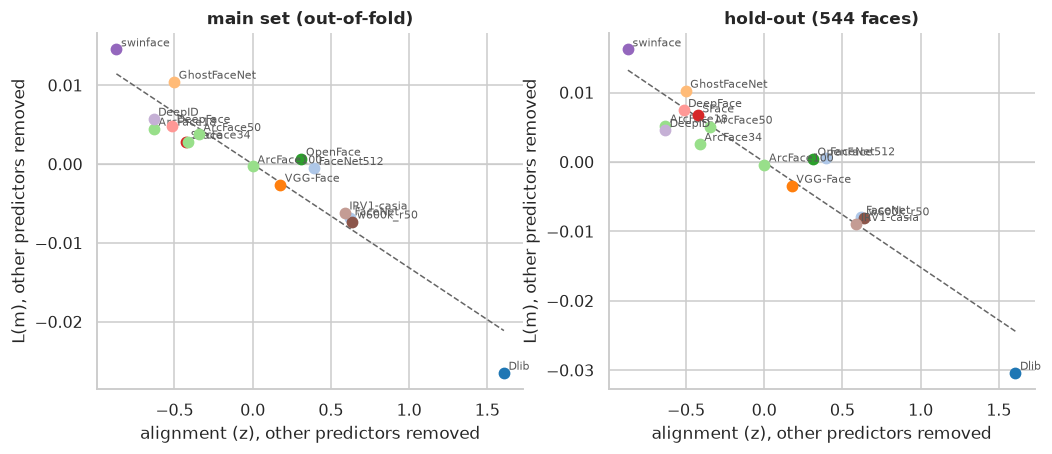

In [70]:
def partial_resid(X, y, j):
    others = np.delete(X, j, axis=1)
    ry = y - others @ ols_b(others, y)
    rx = X[:, j] - others @ ols_b(others, X[:, j])
    return rx, ry

pal = dict(zip(FAMS, sns.color_palette("tab20", N_FAM)))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, col, title in ((axes[0], "L", "main set (out-of-fold)"), (axes[1], "L_hold", "hold-out (544 faces)")):
    rx, ry = partial_resid(X_h1, OUTC[col].to_numpy(), 1)
    for x_, y_, f_, m_ in zip(rx, ry, OUTC.family, OUTC.model):
        ax.scatter(x_, y_, color=pal[f_], s=45, zorder=3)
        ax.annotate(m_, (x_, y_), fontsize=7, xytext=(3, 2), textcoords="offset points", color="0.35")
    bb = np.polyfit(rx, ry, 1)
    xx = np.linspace(rx.min(), rx.max(), 50)
    ax.plot(xx, np.polyval(bb, xx), color="0.4", lw=1, ls="--")
    ax.axhline(0, color="0.8", lw=0.8)
    ax.set_xlabel("alignment (z), other predictors removed")
    ax.set_ylabel("L(m), other predictors removed")
    ax.set_title(title)
save(fig, "A1_h1_partial")
plt.show()

### Independent re-implementation of the H1 step

A second implementation written separately (explicit normal equations, loops over draws and clusters) gets the same draws `V_WILD` and must give the same coefficient, t-statistic, p-value, leave-one-family-out signs and hold-out sign.

In [71]:
def h1_reimpl(df, y, fam_idx, n_fam, V, families):
    d = df.dprime.to_numpy(float); d = d - d.mean()
    cols = [np.ones(len(df))]
    for v in (df["align"].to_numpy(float), d, d ** 2, df.mean_rho.to_numpy(float)):
        cols.append((v - v.mean()) / np.sqrt(((v - v.mean()) ** 2).mean()))
    X = np.array(cols).T
    m, k = X.shape
    XtX_inv = np.linalg.inv(X.T @ X)
    def fit_t(yy):
        b = XtX_inv @ (X.T @ yy)
        e = yy - X @ b
        meat = np.zeros((k, k))
        for g_ in range(n_fam):
            idx = [i for i in range(m) if fam_idx[i] == g_]
            sg = X[idx].T @ e[idx]
            meat += np.outer(sg, sg)
        c = n_fam / (n_fam - 1) * (m - 1) / (m - k)
        se = np.sqrt(c * (XtX_inv @ meat @ XtX_inv)[1, 1])
        return b[1], b[1] / se
    b_obs, t_obs = fit_t(y)
    Xr = np.delete(X, 1, axis=1)
    br = np.linalg.inv(Xr.T @ Xr) @ (Xr.T @ y)
    yr = Xr @ br; ur = y - yr
    count = 0
    for v in V:
        _, ts_ = fit_t(yr + v[fam_idx] * ur)
        count += ts_ <= t_obs
    lofo_ = {}
    for name, g_ in families.items():
        keep = fam_idx != g_
        Xk = X[keep]
        lofo_[name] = float((np.linalg.inv(Xk.T @ Xk) @ (Xk.T @ y[keep]))[1])
    return b_obs, t_obs, (count + 1) / (len(V) + 1), lofo_

b2, t2, p2, lofo2 = h1_reimpl(OUTC, OUTC.L.to_numpy(), fam, N_FAM, V_WILD, FAMS)
b_hold2 = h1_reimpl(OUTC, OUTC.L_hold.to_numpy(), fam, N_FAM, V_WILD[:1], FAMS)[0]
same = (abs(b1 - b2) < 1e-10 and abs(t1 - t2) < 1e-8 and abs(p1 - p2) < 1e-12
        and all(abs(lofo[f] - lofo2[f]) < 1e-10 for f in FAMS) and abs(b_hold - b_hold2) < 1e-10)
print(f"implementation 1: b {b1:+.6f}, t {t1:.4f}, p {p1:.5f}")
print(f"implementation 2: b {b2:+.6f}, t {t2:.4f}, p {p2:.5f}")
assert same, "the two implementations disagree"
print("independent re-implementation: SAME RESULT")

# size check of the test machinery on pure-noise outcomes (no effect, same design)
_g = np.random.default_rng(SEED + 8)
_V = WEBB[_g.integers(0, 6, size=(499, N_FAM))]
_rej = np.mean([wild_t(X_h1, _g.normal(size=N_MODELS) * 0.01 + _g.normal(size=N_FAM)[fam] * 0.007,
                       fam, N_FAM, _V)[2] < H1_ALPHA for _ in range(400)])
print(f"size check: rejection rate with no effect = {100 * _rej:.1f}% (nominal 2.5%; 400 draws, MC SE ~0.8)")

implementation 1: b -0.013147, t -6.5977, p 0.00450
implementation 2: b -0.013147, t -6.5977, p 0.00450
independent re-implementation: SAME RESULT
size check: rejection rate with no effect = 2.2% (nominal 2.5%; 400 draws, MC SE ~0.8)


## 9. H1b: the alignment transformation on unseen faces (secondary)

**Question.** Does Hojjati et al.'s alignment transformation lower excess leakage on faces it never saw?

**The transformation** (Hojjati et al., Zenodo v2, `code/Training.py` and `code/Transformation_matrix_trainer_model.py`, used unchanged): L2-normalise the embedding; PCA fitted on the training faces, keeping min(embedding size, number of training faces) components; then a learned matrix (100 × 100 on the first 100 components, a separate scale for every further component). It is trained on triplets (reference, more similar, less similar) with a loss weighted by the difference in human scores; Adam (learning rate 0.002, clip 0.5), batch 256, 30 epochs, last-epoch weights; per-model L1/L2 penalties from `Regularization_terms.pkl`.

**Headline test, the 544 hold-out faces.** Hojjati et al.'s released matrices (`Trained_Ws_PCs/`) were trained on `Split_data/train.npy`, which contains no hold-out face. For the 14 core models the released matrices are used as published. The two extension models have no released matrix; they are trained with the same code on the same triplets, with the penalties of the model with the same architecture (w600k_r50: ArcFace-50; IRV1-casia: FaceNet512). For each model: transform the main and hold-out embeddings; fit the ridge on the main faces; compute L(m) on the hold-out faces. **ΔL = L_raw − L_aligned** (> 0: the transformation lowers leakage). One-sided Wilcoxon signed-rank over models; family-clustered bootstrap 95% interval for mean ΔL.

**Controls,** through the same steps: a **placebo** transformation (same code and triplets, but the order of each triplet flipped at random) and a **matched-spectrum random** transformation (the matrix's singular vectors replaced by random orthogonal ones, singular values kept). **Manipulation check:** alignment on trials the transformation never saw (from the supporting analysis).

**Supporting analysis** (`H1B_CV`): one 5-fold face-level partition of the main set; each fold's transformation is trained (same code) on the released triplets that contain none of that fold's faces.

**Validation (runs in both modes, on the real released embeddings of `VALIDATE_MODELS`; no outcome is involved).** The training code, run here on `train.npy` with the published penalties, must reproduce the alignment of the released matrix: the released value must lie within the range of `VALIDATE_SEEDS` retraining seeds ± 0.01. Training is random (their `Note.txt`), so the comparison is with a range, not a single number.

In synthetic mode there are no released matrices for the simulated embeddings: every model is trained with the same code on the released triplet layout, re-ordered by the synthetic similarity judgments. `FAST` uses 1 epoch instead of 30, so the transformations are far from trained and the manipulation check usually fails in the fast synthetic run; it tests the code path only. The validation always uses 30 epochs.

In [72]:
import sys, pickle, gc
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
try:
    import tensorflow as tf
    import sklearn
    from sklearn.decomposition import PCA
except ImportError as ex:
    raise ImportError("H1b needs TensorFlow and scikit-learn in this venv: pip install 'numpy<2' scikit-learn") from ex
HOJ_CODE = os.path.join(ZEN, "code")
sys.path.insert(0, HOJ_CODE)
from Transformation_matrix_trainer_model import Transformation_matrix_trainer

H1B_EPOCHS = 1 if (MODE == "synthetic" and FAST) else 30
VALIDATE, VALIDATE_MODELS, VALIDATE_SEEDS, VALIDATE_TOL = True, ["Dlib", "SFace"], 3, 0.01
REG = pickle.load(open(os.path.join(ZEN, "Regularization_terms.pkl"), "rb"))
REG_PROXY = {"w600k_r50": "ARCFace50_glint360k_embs", "IRV1-casia": "Facenet512_embs"}
TRIP = np.load(os.path.join(ZEN, "Split_data", "train.npy")).astype(int)
TRIP_SC = np.load(os.path.join(ZEN, "Split_data", "train_scores.npy")).astype(np.float32)
assert not np.isin(TRIP, HOLD - 1).any(), "released triplets contain a hold-out face"
print(f"TensorFlow {tf.__version__}, scikit-learn {sklearn.__version__}; triplets {len(TRIP):,}; epochs {H1B_EPOCHS}")

def reg_for(name):
    stem = CORE_STEMS.get(name, REG_PROXY.get(name))
    return float(REG["l1"][stem]), float(REG["l2"][stem])

class LinearTransform:
    """(L2-normalised embedding - PCA mean) @ PCA components^T @ A  (Hojjati et al.'s transformed space)."""
    def __init__(self, mu, comps, A):
        self.mu, self.comps, self.A = mu, comps, A
    def __call__(self, E):
        return (l2norm_rows(E) - self.mu) @ self.comps.T @ self.A
    def spectrum_matched(self, seed):
        U, S, Vt = np.linalg.svd(self.A)
        g = np.random.default_rng(seed)
        def haar(q):
            Qm, Rm = np.linalg.qr(g.normal(size=(q, q)))
            return Qm * np.sign(np.diag(Rm))
        return LinearTransform(self.mu, self.comps, haar(len(S)) @ np.diag(S) @ haar(len(S)).T)

def released_transform(name):
    stem, base = CORE_STEMS[name], os.path.join(ZEN, "Trained_Ws_PCs")
    mu = np.load(os.path.join(base, "PCs", f"{stem}_PCA_mean.npy"))
    comps = np.load(os.path.join(base, "PCs", f"{stem}_PCA_trans.npy"))
    A = np.load(os.path.join(base, "Ws", f"{stem}_W.npy"))
    assert comps.shape[0] == A.shape[0] == A.shape[1] and comps.shape[1] == mu.shape[0], (name, comps.shape, A.shape)
    return LinearTransform(mu, comps, A)

def train_hojjati(E, trip, tsc, l1, l2, seed, epochs):
    """Training.py, step by step, with the triplets streamed instead of held in one array (same arithmetic)."""
    tf.keras.backend.clear_session()                # free the previous model's graph (memory)
    gc.collect()
    X = l2norm_rows(E)
    faces = np.unique(trip)
    total = min(X.shape[1], len(faces))
    pca = PCA(n_components=total).fit(X[faces])
    Z = pca.transform(X).astype(np.float32)
    tf.keras.utils.set_random_seed(int(seed))
    model = Transformation_matrix_trainer(total_dims=total, n_PCs=100, l1_regularization=l1, l2_regularization=l2)
    model.build((3, total))
    inp = tf.keras.layers.Input(shape=(3, total), name="input")
    _ = tf.keras.Model(inp, model(inp))
    model.reinitialize_weights()
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.002, clipvalue=0.5), loss="binary_crossentropy")
    Zt = tf.constant(Z)

    @tf.autograph.experimental.do_not_convert
    def to_batch(t, s):                             # the same (3, dims + 1) rows Training.py builds in X_train
        return tf.concat([tf.gather(Zt, t), s[:, :, None]], axis=2), tf.zeros((tf.shape(t)[0], 1))

    ds = (tf.data.Dataset.from_tensor_slices((trip.astype(np.int32), tsc.astype(np.float32)))
          .shuffle(len(trip), seed=int(seed), reshuffle_each_iteration=True).batch(256)
          .map(to_batch).prefetch(2))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model.fit(ds, epochs=epochs, verbose=0)
    w = model.get_weights()
    del model, ds, Zt
    A = np.zeros((total, total))
    A[:100, :100] = w[0]
    if total > 100:
        A[100:, 100:] = np.diag(w[1])
    return LinearTransform(pca.mean_, pca.components_, A)

def alignment_on(Z, trials, scores):
    """Mean Spearman rho between model and human orderings on raw distances (Hojjati et al.'s utils)."""
    faces = np.unique(trials)
    pos = np.searchsorted(faces, trials)
    D = squareform(pdist(np.asarray(Z, np.float64)[faces], "euclidean"))   # memory-light for wide embeddings
    d = D[pos[:, :1], pos[:, 1:]]
    mo = np.argsort(d, axis=1) + 1
    hu = np.argsort(scores[:, 1:], axis=1) + 1
    return float(np.mean(1 - 6 * ((hu - mo) ** 2).sum(1) / (4 * (16 - 1))))

# triplets for this mode: released (real) or the released layout re-ordered by the synthetic judgments
if MODE == "real":
    TRIP_USE, TSC_USE = TRIP, TRIP_SC
else:
    pair_trial = {}
    for t, row in enumerate(TRIALS):
        for i in range(1, 5):
            for j in range(i + 1, 5):
                pair_trial.setdefault((row[0], frozenset((row[i], row[j]))), t)
    ranks = 1 + (SCORES[:, 1:, None] > SCORES[:, None, 1:]).sum(2)          # within-trial rank, ties shared
    TRIP_USE, TSC_USE = TRIP.copy(), np.zeros_like(TRIP_SC)
    for n, (r_, a_, b_) in enumerate(TRIP):
        t = pair_trial[(r_, frozenset((a_, b_)))]
        pos = {TRIALS[t, k]: ranks[t, k - 1] for k in range(1, 5)}
        ra, rb = pos[a_], pos[b_]
        if ra > rb:
            TRIP_USE[n, 1], TRIP_USE[n, 2], ra, rb = b_, a_, rb, ra
        TSC_USE[n] = (r_, ra, rb)
flip = np.random.default_rng(SEED + 21).random(len(TRIP_USE)) < 0.5
TRIP_PL, TSC_PL = TRIP_USE.copy(), TSC_USE.copy()
TRIP_PL[flip, 1], TRIP_PL[flip, 2] = TRIP_USE[flip, 2], TRIP_USE[flip, 1]
TSC_PL[flip, 1], TSC_PL[flip, 2] = TSC_USE[flip, 2], TSC_USE[flip, 1]

TensorFlow 2.21.0, scikit-learn 1.9.1; triplets 140,879; epochs 1


### Validation of the training code against the released matrices

In [73]:
val_rows = []
if VALIDATE:
    f = os.path.join(REPO, "results", "analysis", "transform_validation.csv")
    if os.path.exists(f):
        val_tab = pd.read_csv(f)
    else:
        for name in VALIDATE_MODELS:
            E = np.load(os.path.join(ZEN, "Similarity_task_images_embeds", f"{CORE_STEMS[name]}.npy")).astype(np.float64)
            l1, l2 = reg_for(name)
            a_raw = alignment_on(l2norm_rows(E), TRIALS, SCORES_REAL)
            a_rel = alignment_on(released_transform(name)(E), TRIALS, SCORES_REAL)
            a_seeds = [alignment_on(train_hojjati(E, TRIP, TRIP_SC, l1, l2, seed=s, epochs=30)(E), TRIALS, SCORES_REAL)
                       for s in range(VALIDATE_SEEDS)]
            ok = min(a_seeds) - VALIDATE_TOL <= a_rel <= max(a_seeds) + VALIDATE_TOL
            val_rows.append(dict(model=name, align_raw=a_raw, align_released_W=a_rel,
                                 align_retrained_min=min(a_seeds), align_retrained_max=max(a_seeds), passed=ok))
            print(f"{name}: raw {a_raw:.4f}; released W {a_rel:.4f}; retrained {min(a_seeds):.4f}-{max(a_seeds):.4f} "
                  f"-> {'PASS' if ok else 'FAIL'}")
        val_tab = pd.DataFrame(val_rows)
        val_tab.to_csv(f, index=False)
    print(val_tab.round(4).to_string(index=False))
    TRANSFORM_VALID = bool(val_tab.passed.all())
    print(f"transformation code validation: {'PASS' if TRANSFORM_VALID else 'FAIL'} (all trials, alignment)")
else:
    TRANSFORM_VALID = None
if MODE == "real" and TRANSFORM_VALID is False:
    print("Rules and fallbacks: the training code does not reproduce the released matrices -> H1b is reported as not tested")

model  align_raw  align_released_W  align_retrained_min  align_retrained_max  passed
 Dlib     0.3208            0.3947               0.3944               0.3962    True
SFace     0.1958            0.3720               0.3717               0.3723    True
transformation code validation: PASS (all trials, alignment)


### Transformations, controls and ΔL per model

In [74]:
h1b_rows = []
t0 = time.time()
folds5 = make_folds(MAIN, strata_main, 5, 1, SEED + 500)[0]
for r in MODELS.itertuples():
    f = os.path.join(CACHE, f"h1b_{r.model}_e{H1B_EPOCHS}.json")
    if os.path.exists(f):
        h1b_rows.append(json.load(open(f))); continue
    E = EMB[r.model]
    l1, l2 = reg_for(r.model)
    if MODE == "real" and r.source == "release":
        T_al, how = released_transform(r.model), "released"
    else:
        T_al, how = train_hojjati(E, TRIP_USE, TSC_USE, l1, l2, seed=SEED, epochs=H1B_EPOCHS), "trained"
    variants = {"aligned": T_al,
                "placebo": train_hojjati(E, TRIP_PL, TSC_PL, l1, l2, seed=SEED, epochs=H1B_EPOCHS),
                "matched_random": T_al.spectrum_matched(SEED + 5)}
    row = dict(model=r.model, family=r.family, transform=how,
               L_raw=float(OUTC.set_index("model").loc[r.model, "L_hold"]))
    for name, T_ in variants.items():
        Z = T_(E)
        (Ph,), _ = ridge_cv_fit_predict(Z[MAIN - 1], YALL[MAIN - 1], [Z[HOLD - 1]], seed=SEED + 99)
        row[f"L_{name}"] = excess_leakage(Ph[:, k14], Yh14, R14, r_hold)["L"]
    if H1B_CV:
        oof_al, a_raw, a_al = np.zeros((len(MAIN), len(TARGETS))), [], []
        for k in range(5):
            te = folds5 == k
            fold_faces = MAIN[te] - 1
            keep = ~np.isin(TRIP_USE, fold_faces).any(1)
            T_k = train_hojjati(E, TRIP_USE[keep], TSC_USE[keep], l1, l2, seed=SEED + k, epochs=H1B_EPOCHS)
            Z = T_k(E)
            (P,), _ = ridge_cv_fit_predict(Z[MAIN - 1][~te], YALL[MAIN - 1][~te], [Z[MAIN - 1][te]], seed=SEED + k)
            oof_al[te] = P
            unseen = np.isin(TRIALS, fold_faces).any(1)
            a_raw.append(alignment_on(l2norm_rows(E), TRIALS[unseen], SCORES[unseen]))
            a_al.append(alignment_on(Z, TRIALS[unseen], SCORES[unseen]))
        oof_raw = PRED[r.model]["oof"][0]
        row["L_cv_raw"] = excess_leakage(oof_raw[:, k14], Ym14, R14, r_main)["L"]
        row["L_cv_aligned"] = excess_leakage(oof_al[:, k14], Ym14, R14, r_main)["L"]
        row["align_unseen_raw"], row["align_unseen_aligned"] = float(np.mean(a_raw)), float(np.mean(a_al))
    json.dump(row, open(f, "w"))
    h1b_rows.append(row)
    print(f"{r.model:14s} {how:8s} done ({time.time() - t0:5.0f}s)")
H1B = pd.DataFrame(h1b_rows)
for v in ("aligned", "placebo", "matched_random"):
    H1B[f"dL_{v}"] = H1B.L_raw - H1B[f"L_{v}"]
if H1B_CV:
    H1B["dL_cv"] = H1B.L_cv_raw - H1B.L_cv_aligned
H1B.to_csv(os.path.join(OUT, "h1b_by_model.csv"), index=False)

def family_boot_mean(vals, fam_idx, B, seed):
    g = np.random.default_rng(seed)
    fams = np.unique(fam_idx)
    by = [vals[fam_idx == f] for f in fams]
    means = np.empty(B)
    for b in range(B):
        pick = g.integers(0, len(fams), len(fams))
        means[b] = np.concatenate([by[i] for i in pick]).mean()
    return np.percentile(means, [2.5, 97.5])

h1b = {}
for v in ["aligned", "placebo", "matched_random"] + (["cv"] if H1B_CV else []):
    d = H1B[f"dL_{v}"].to_numpy()
    w = stats.wilcoxon(d, alternative="greater")
    lo, hi = family_boot_mean(d, fam, B_CLUSTER, SEED + 31)
    h1b[v] = dict(mean_dL=float(d.mean()), ci95=[float(lo), float(hi)], wilcoxon_p_greater=float(w.pvalue),
                  n_positive=int((d > 0).sum()))
    print(f"{v:15s} mean ΔL {d.mean():+.4f} [{lo:+.4f}, {hi:+.4f}]  Wilcoxon p = {w.pvalue:.4f}  "
          f"({(d > 0).sum()}/{len(d)} models lower)")
if H1B_CV:
    h1b["manipulation_check"] = dict(mean_align_unseen_raw=float(H1B.align_unseen_raw.mean()),
                                     mean_align_unseen_aligned=float(H1B.align_unseen_aligned.mean()),
                                     n_models_improved=int((H1B.align_unseen_aligned > H1B.align_unseen_raw).sum()))
    print(f"manipulation check: alignment on unseen trials {H1B.align_unseen_raw.mean():.4f} -> "
          f"{H1B.align_unseen_aligned.mean():.4f} ({h1b['manipulation_check']['n_models_improved']}/{N_MODELS} improved)")
h1b["transform_impl"] = TRANSFORM_IMPL
h1b["epochs"] = H1B_EPOCHS
h1b["transform_validation_passed"] = TRANSFORM_VALID
if MODE == "real" and TRANSFORM_VALID is False:
    h1b["status"] = "not tested (training code did not reproduce the released matrices)"
dump(h1b, "h1b_result.json")

aligned         mean ΔL -0.0226 [-0.0402, -0.0091]  Wilcoxon p = 0.9995  (3/16 models lower)
placebo         mean ΔL -0.0024 [-0.0068, +0.0021]  Wilcoxon p = 0.9123  (5/16 models lower)
matched_random  mean ΔL +0.0016 [-0.0003, +0.0041]  Wilcoxon p = 0.2983  (8/16 models lower)
cv              mean ΔL -0.0242 [-0.0416, -0.0087]  Wilcoxon p = 0.9995  (3/16 models lower)
manipulation check: alignment on unseen trials 0.0997 -> 0.0546 (0/16 improved)


## 10. Q2: factor structure of predicted impressions (exploratory)

For each model, the 14 out-of-fold predicted trait scores (averaged over repeats) are summarised by: the share of variance on the first component, the effective rank (exp of the entropy of the normalised eigenvalues), the number of components above the 95th percentile of column-shuffled data (parallel analysis), and the Tucker congruence of the first two components with the human structure.

**Noise-matched null:** the human scores with noise added until each trait's correlation with the original equals the model's ρᵢ, repeated `N_NULL_Q2` times. Richness beyond noise = observed − null median. Across models: Spearman ρ with alignment, with a family-clustered bootstrap interval.

In [75]:
def structure(Xs, g, n_perm):
    C = np.corrcoef(Xs.T)
    ev, vec = np.linalg.eigh(C)
    ev, vec = ev[::-1], vec[:, ::-1]
    p = np.clip(ev, 1e-12, None) / ev.sum()
    eff = float(np.exp(-(p * np.log(p)).sum()))
    null = np.array([np.linalg.eigvalsh(np.corrcoef(np.column_stack([g.permutation(c) for c in Xs.T]).T))[::-1]
                     for _ in range(n_perm)])
    n_pa = int((ev > np.percentile(null, 95, axis=0)).sum()) if n_perm else np.nan
    return dict(pc1=float(ev[0] / ev.sum()), eff_rank=eff, n_parallel=n_pa, loadings=vec[:, :2] * np.sqrt(ev[:2]))

def tucker(a, b):
    return float(abs(a @ b) / np.sqrt((a @ a) * (b @ b)))

g2 = np.random.default_rng(SEED + 40)
hum = structure(Ym14, g2, N_PERM_Q2)
q2_rows = []
for r in MODELS.itertuples():
    Pm = PRED[r.model]["oof"].mean(0)[:, k14]
    obs = structure(Pm, g2, N_PERM_Q2)
    rho = np.clip(TRACC.loc[r.model, TRAITS_14].to_numpy(float), 0.05, 0.99)
    Yz = (Ym14 - Ym14.mean(0)) / Ym14.std(0)
    nulls = []
    for _ in range(N_NULL_Q2):
        noise_sd = np.sqrt(1 / rho ** 2 - 1)
        nulls.append(structure(Yz + g2.normal(size=Yz.shape) * noise_sd, g2, 0))
    null_eff = np.median([n_["eff_rank"] for n_ in nulls])
    null_pc1 = np.median([n_["pc1"] for n_ in nulls])
    q2_rows.append(dict(model=r.model, family=r.family, align=r.align_usafd, pc1=obs["pc1"], eff_rank=obs["eff_rank"],
                        n_parallel=obs["n_parallel"], tucker1=tucker(obs["loadings"][:, 0], hum["loadings"][:, 0]),
                        tucker2=tucker(obs["loadings"][:, 1], hum["loadings"][:, 1]),
                        eff_rank_null=null_eff, richness=obs["eff_rank"] - null_eff, pc1_beyond=obs["pc1"] - null_pc1))
Q2 = pd.DataFrame(q2_rows)
Q2.to_csv(os.path.join(OUT, "q2_structure.csv"), index=False)

def spearman_with_ci(x, y, fam_idx, B, seed):
    rho = stats.spearmanr(x, y)[0]
    g = np.random.default_rng(seed)
    fams = np.unique(fam_idx)
    bs = []
    for _ in range(B):
        pick = g.integers(0, len(fams), len(fams))
        idx = np.concatenate([np.flatnonzero(fam_idx == fams[i]) for i in pick])
        if len(np.unique(x[idx])) > 2:
            bs.append(stats.spearmanr(x[idx], y[idx])[0])
    return float(rho), [float(v) for v in np.nanpercentile(bs, [2.5, 97.5])]

q2 = {k: spearman_with_ci(Q2["align"].to_numpy(), Q2[k].to_numpy(), fam, B_CLUSTER, SEED + 41)
      for k in ("richness", "pc1_beyond", "tucker1")}
# sensitivity: all 20 attributes
Ym20 = YALL[MAIN - 1][:, :20]
Yz20 = (Ym20 - Ym20.mean(0)) / Ym20.std(0)
rich20 = []
for r in MODELS.itertuples():
    P20 = PRED[r.model]["oof"].mean(0)[:, :20]
    rho20 = np.clip([np.corrcoef(P20[:, j], Ym20[:, j])[0, 1] for j in range(20)], 0.05, 0.99)
    obs20 = structure(P20, g2, 0)["eff_rank"]
    null20 = np.median([structure(Yz20 + g2.normal(size=Yz20.shape) * np.sqrt(1 / rho20 ** 2 - 1), g2, 0)["eff_rank"]
                        for _ in range(N_NULL_Q2)])
    rich20.append(obs20 - null20)
Q2["richness_20"] = rich20
Q2.to_csv(os.path.join(OUT, "q2_structure.csv"), index=False)
q2["richness_20"] = spearman_with_ci(Q2["align"].to_numpy(), Q2["richness_20"].to_numpy(), fam, B_CLUSTER, SEED + 42)
q2["human"] = dict(pc1=hum["pc1"], eff_rank=hum["eff_rank"], n_parallel=hum["n_parallel"])
dump(q2, "q2_result.json")
print(Q2.round(3).to_string(index=False))
for k in ("richness", "pc1_beyond", "tucker1", "richness_20"):
    print(f"Spearman(alignment, {k}) = {q2[k][0]:+.2f}  95% CI {np.round(q2[k][1], 2).tolist()}")

       model          family  align   pc1  eff_rank  n_parallel  tucker1  tucker2  eff_rank_null  richness  pc1_beyond  richness_20
        Dlib            Dlib  0.297 0.744     2.849           2    1.000    1.000          7.442    -4.594       0.272       -6.908
  FaceNet512         FaceNet  0.248 0.761     2.680           2    0.999    1.000          7.136    -4.456       0.273       -6.784
     FaceNet         FaceNet  0.248 0.772     2.551           2    0.999    1.000          7.426    -4.876       0.299       -7.379
    VGG-Face        VGG-Face  0.238 0.753     2.784           2    0.999    1.000          7.062    -4.279       0.262       -6.511
GhostFaceNet    GhostFaceNet  0.190 0.786     2.413           2    0.999    1.000          7.229    -4.816       0.304       -7.285
    OpenFace        OpenFace  0.179 0.812     2.186           2    0.999    0.997          7.731    -5.545       0.355       -8.348
   ArcFace18         ArcFace  0.178 0.778     2.494           2    0.999    

## 11. Q3: demographic gaps (exploratory)

For each trait and contrast on the main set: the standardised gap in predicted scores minus the standardised gap in human scores of the same faces. Contrasts: female vs male and White vs non-White (Cohen's d, pooled SD); age (Spearman correlation with the continuous age score). The model index is the mean absolute excess over the 14 traits × 3 contrasts. Race × gender cells (each cell vs all other faces) are reported descriptively; cells with fewer than 50 faces are flagged. Across models: Spearman ρ of the index with alignment.

In [76]:
def cohen_d(v, grp):
    a, b = v[grp == 1], v[grp == 0]
    sp = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / sp

dm = demo.loc[MAIN]
contrasts = {"female": dm.female.to_numpy(), "white": dm.white.to_numpy()}
age_ok = dm.age.notna().to_numpy()
cells = {f"{w}_{g_}": ((dm.white == (w == "White")) & (dm.gender == g_)).astype(int).to_numpy()
         for w in ("White", "nonWhite") for g_ in ("Female", "Male")}

def gaps(S):
    out = {}
    for c, grp in contrasts.items():
        out[c] = np.array([cohen_d(S[:, i], grp) for i in range(14)])
    out["age"] = np.array([stats.spearmanr(S[age_ok, i], dm.age.to_numpy()[age_ok])[0] for i in range(14)])
    return out

hum_gap = gaps(Ym14)
cell_n = {k: int(v.sum()) for k, v in cells.items()}
q3_rows, cell_rows = [], []
for r in MODELS.itertuples():
    Pm = PRED[r.model]["oof"].mean(0)[:, k14]
    pg = gaps(Pm)
    ex = {c: pg[c] - hum_gap[c] for c in pg}
    q3_rows.append(dict(model=r.model, family=r.family, align=r.align_usafd,
                        index=float(np.mean([np.abs(ex[c]).mean() for c in ex])),
                        **{f"mean_abs_excess_{c}": float(np.abs(ex[c]).mean()) for c in ex}))
    for cname, grp in cells.items():
        cell_rows.append(dict(model=r.model, cell=cname, n=cell_n[cname], descriptive_only=cell_n[cname] < CELL_MIN,
                              mean_abs_excess=float(np.mean([abs(cohen_d(Pm[:, i], grp) - cohen_d(Ym14[:, i], grp))
                                                             for i in range(14)]))))
Q3 = pd.DataFrame(q3_rows)
Q3.to_csv(os.path.join(OUT, "q3_disparity.csv"), index=False)
pd.DataFrame(cell_rows).to_csv(os.path.join(OUT, "q3_cells.csv"), index=False)
q3 = dict(index=spearman_with_ci(Q3["align"].to_numpy(), Q3["index"].to_numpy(), fam, B_CLUSTER, SEED + 51),
          cell_n=cell_n)
dump(q3, "q3_result.json")
print(Q3.round(4).to_string(index=False))
print(f"cells (main set): {cell_n}")
print(f"Spearman(alignment, disparity index) = {q3['index'][0]:+.2f}  95% CI {np.round(q3['index'][1], 2).tolist()}")

       model          family  align  index  mean_abs_excess_female  mean_abs_excess_white  mean_abs_excess_age
        Dlib            Dlib 0.2971 0.0206                  0.0244                 0.0310               0.0064
  FaceNet512         FaceNet 0.2479 0.0207                  0.0281                 0.0265               0.0076
     FaceNet         FaceNet 0.2478 0.0207                  0.0298                 0.0255               0.0067
    VGG-Face        VGG-Face 0.2384 0.0205                  0.0258                 0.0290               0.0067
GhostFaceNet    GhostFaceNet 0.1902 0.0203                  0.0266                 0.0263               0.0079
    OpenFace        OpenFace 0.1787 0.0242                  0.0263                 0.0353               0.0110
   ArcFace18         ArcFace 0.1782 0.0204                  0.0261                 0.0264               0.0088
       SFace           SFace 0.1761 0.0195                  0.0220                 0.0286               0.0077
 

## 12. Q4: memorability (exploratory)

Target: logit hit rate (rates clipped to [0.005, 0.995]); sensitivity targets: logit false-alarm rate and memorability d′. For each target, the association across models between alignment and out-of-fold prediction accuracy (Spearman ρ). Memorability is **distinct** if its association falls below the 25th percentile of the same association across the 14 traits. (Dividing accuracy by a per-target reliability ceiling would not change a rank correlation across models, so no ceiling is applied.)

In [77]:
acc = {}
for j, t in enumerate(TARGETS):
    acc[t] = np.array([np.mean([np.corrcoef(PRED[m]["oof"][k][:, j], YALL[MAIN - 1][:, j])[0, 1]
                                for k in range(N_REPEAT)]) for m in MODELS.model])
assoc = {t: float(stats.spearmanr(MODELS.align_usafd, acc[t])[0]) for t in TRAITS_14 + MEM_TARGETS}
p25 = float(np.percentile([assoc[t] for t in TRAITS_14], 25))
q4 = dict(assoc_traits={t: assoc[t] for t in TRAITS_14}, p25_traits=p25,
          memorability={t: dict(assoc=assoc[t], distinct=assoc[t] < p25) for t in MEM_TARGETS},
          accuracy_mem_logit_hr=dict(zip(MODELS.model, acc["mem_logit_hr"].round(4))))
dump(q4, "q4_result.json")
print(f"association (alignment vs accuracy) across the 14 traits: 25th percentile {p25:+.2f}")
for t in MEM_TARGETS:
    print(f"  {t:14s} {assoc[t]:+.2f} -> {'distinct' if assoc[t] < p25 else 'not distinct'}")

association (alignment vs accuracy) across the 14 traits: 25th percentile +0.32
  mem_logit_hr   -0.46 -> distinct
  mem_logit_far  +0.43 -> not distinct
  mem_dprime     -0.48 -> distinct


## 13. CFD external check (descriptive)

Predictions for the 597 CFD faces come from each model's fit on the main faces (raw embeddings). CFD raters judged faces relative to people of the same race and gender, so the check uses pooled within-cell correlations: Fisher-z average over race × gender cells (weights n − 3), cells with at least 20 faces, for attractive, trustworthy and happy.

In [78]:
cfd_idx = [TARGETS.index(t) for t in CFD_TRAITS]
cells_cfd = pd.Series(CFD_CELL).value_counts()
use_cells = cells_cfd[cells_cfd >= CFD_MIN_CELL].index
cfd_rows = []
for r in MODELS.itertuples():
    Pc = PRED[r.model]["cfd"][:, cfd_idx]
    row = dict(model=r.model, family=r.family, align=r.align_usafd)
    for j, t in enumerate(CFD_TRAITS):
        zsum = wsum = 0.0
        for c in use_cells:
            sel = CFD_CELL == c
            rr = np.corrcoef(Pc[sel, j], CFDY[sel, j])[0, 1]
            zsum += (sel.sum() - 3) * np.arctanh(rr); wsum += sel.sum() - 3
        row[f"r_{t}"] = float(np.tanh(zsum / wsum))
    row["r_mean"] = float(np.mean([row[f"r_{t}"] for t in CFD_TRAITS]))
    cfd_rows.append(row)
CFDR = pd.DataFrame(cfd_rows)
CFDR.to_csv(os.path.join(OUT, "cfd_check.csv"), index=False)
print(f"cells used: {list(use_cells)}")
print(CFDR.round(3).to_string(index=False))

cells used: ['Black/Female', 'Black/Male', 'White/Male', 'White/Female', 'Asian/Female', 'Latino/Female', 'Asian/Male', 'Latino/Male']
       model          family  align  r_attractive  r_trustworthy  r_happy  r_mean
        Dlib            Dlib  0.297         0.904          0.882    0.882   0.889
  FaceNet512         FaceNet  0.248         0.908          0.906    0.904   0.906
     FaceNet         FaceNet  0.248         0.893          0.894    0.888   0.892
    VGG-Face        VGG-Face  0.238         0.914          0.912    0.907   0.911
GhostFaceNet    GhostFaceNet  0.190         0.906          0.903    0.901   0.903
    OpenFace        OpenFace  0.179         0.863          0.882    0.881   0.875
   ArcFace18         ArcFace  0.178         0.908          0.906    0.905   0.906
       SFace           SFace  0.176         0.871          0.890    0.883   0.881
    DeepFace        DeepFace  0.168         0.917          0.913    0.908   0.913
   ArcFace34         ArcFace  0.157         0

## 14. Synthetic recovery check (synthetic mode only)

The synthetic world has a known truth. Two checks:
1. **Oracle L(m).** For each model, a large fresh sample (10,000 faces: 7,500 to fit, 2,500 to evaluate) from the same world gives the model's population L(m). The pipeline's L(m) at 1,678 faces must track it (Spearman ρ across models ≥ 0.8) without a large bias.
2. **Decision.** With `SYN_KAPPA` > 0 the built-in effect should usually make H1 supported; with `SYN_KAPPA = 0` it should usually not.

In [79]:
if MODE == "synthetic":
    world = SYN[1]
    g = np.random.default_rng(SEED + 300)
    n_big = 10_000
    T = g.multivariate_normal(np.zeros(20), world["S20"], size=n_big)
    w, V = np.linalg.eigh(world["S20"]); v1 = V[:, -1] * np.sign(V[:, -1].sum()); load = v1 * np.sqrt(w[-1])
    gen = T @ v1 / np.sqrt(w[-1]); spec = T - np.outer(gen, load)
    Yb = np.sqrt(R20) * T + np.sqrt(1 - R20) * g.normal(size=T.shape)
    mem_b = 0.25 * T[:, 1] + 0.2 * T[:, 3] + 0.9 * g.normal(size=n_big)
    Fb = g.normal(size=(n_big, 8))
    za = zs(MODELS.align_usafd)
    oracle = []
    for (r, ls, a) in zip(MODELS.itertuples(), world["log_s"], za):
        sig = np.column_stack([gen, np.exp(ls) * spec, 0.6 * mem_b, (0.5 + 0.25 * a) * Fb])
        M = g.normal(size=(sig.shape[1], r.emb_dim)) / np.sqrt(sig.shape[1])
        Eb = l2norm_rows(sig @ M * 3.0 + g.normal(size=(n_big, r.emb_dim)))
        tr, te = slice(0, 7_500), slice(7_500, None)
        (Pb,), _ = ridge_cv_fit_predict(Eb[tr], Yb[tr][:, :14], [Eb[te]], seed=SEED)
        oracle.append(excess_leakage(Pb, Yb[te][:, :14], R14)["L"])
    OUTC["L_oracle"] = oracle
    rho_or = stats.spearmanr(OUTC.L, OUTC.L_oracle)[0]
    bias = float((OUTC.L - OUTC.L_oracle).mean())
    print(f"oracle vs pipeline L(m): Spearman {rho_or:.2f}; mean bias {bias:+.4f} "
          f"(oracle range {min(oracle):+.3f} to {max(oracle):+.3f})")
    print(f"built-in effect SYN_KAPPA = {SYN_KAPPA}: H1 {'SUPPORTED' if H1_SUPPORTED else 'NOT SUPPORTED'}")
    syn = dict(kappa=SYN_KAPPA, oracle_spearman=float(rho_or), oracle_bias=bias, h1_supported=H1_SUPPORTED)
    dump(syn, "synthetic_recovery.json")
    assert rho_or >= 0.8, "the pipeline does not track the oracle L(m)"
    print("recovery check: PASS")
else:
    print("real mode: no synthetic check")

oracle vs pipeline L(m): Spearman 1.00; mean bias +0.0040 (oracle range -0.004 to +0.043)
built-in effect SYN_KAPPA = 0.6: H1 SUPPORTED
recovery check: PASS


## 15. Facts table

In [80]:
facts = dict(mode=MODE, registration=REGISTRATION or None, n_models=N_MODELS, n_families=N_FAM,
             folds=f"{K_OUTER}x{N_REPEAT}", inner=K_INNER, B_wild=B_WILD, transform=TRANSFORM_IMPL,
             h1=dict(supported=H1_SUPPORTED, b=b1, t=t1, p=p1, b_holdout=b_hold,
                     lofo_min=min(lofo.values()), lofo_max=max(lofo.values())),
             h1b={k: v for k, v in h1b.items() if k != "transform_impl"},
             q2={k: q2[k] for k in ("richness", "pc1_beyond", "tucker1")}, q3=q3["index"],
             q4={t: q4["memorability"][t] for t in MEM_TARGETS},
             cfd_mean_r=dict(zip(CFDR.model, CFDR.r_mean.round(3))),
             numpy=np.__version__, pandas=pd.__version__)
dump(facts, "facts_03.json")
for k, v in facts.items():
    print(f"{k:14s} {v}")

mode           synthetic
registration   None
n_models       16
n_families     12
folds          5x1
inner          5
B_wild         1999
transform      hojjati
h1             {'supported': True, 'b': -0.013146806620967733, 't': -6.597666682494362, 'p': 0.0045, 'b_holdout': -0.01518008041992117, 'lofo_min': -0.014287908448990675, 'lofo_max': -0.01050807133477826}
h1b            {'aligned': {'mean_dL': -0.022571859210311067, 'ci95': [-0.040188697471283605, -0.009068839481259063], 'wilcoxon_p_greater': 0.9994964599609375, 'n_positive': 3}, 'placebo': {'mean_dL': -0.0023795904851130977, 'ci95': [-0.006843792886108367, 0.0020768613681902254], 'wilcoxon_p_greater': 0.912322998046875, 'n_positive': 5}, 'matched_random': {'mean_dL': 0.0015853382202622095, 'ci95': [-0.0002880827130206589, 0.004054427572391721], 'wilcoxon_p_greater': 0.2982940673828125, 'n_positive': 8}, 'cv': {'mean_dL': -0.024156623581461048, 'ci95': [-0.04157641990703392, -0.008721554966529646], 'wilcoxon_p_greater': 0.999496